<div dir="rtl">

# کارگاه جلسه ۲۷ — خوشه‌بندی سلسله‌مراتبی

این دفترچه ابزارهایی را نشان می‌دهد که در جزوه نیامده‌اند و تمرین عملی کلاس را با پاسخ دارد. نوشتن این کدها در امتحان پرسیده نمی‌شود.

## ۱. ماتریس فاصله دلخواه: داده ترکیبی مشتریان

جنسیت یک ویژگی کیفی است. یک فاصله ساده شبیه گاور می‌سازیم: برای ویژگی‌های عددی فاصله منهتن تقسیم بر دامنه، و برای جنسیت صفر یا یک؛ سپس میانگین می‌گیریم. ماتریس حاصل را با `metric="precomputed"` به `AgglomerativeClustering` می‌دهیم (روش وارد مجاز نیست).

</div>

In [1]:
import numpy as np
import pandas as pd
from sklearn.metrics import pairwise_distances
from sklearn.cluster import AgglomerativeClustering

url = "https://raw.githubusercontent.com/tirthajyoti/Machine-Learning-with-Python/master/Datasets/Mall_Customers.csv"
mall = pd.read_csv(url)
num = mall[["Age", "Annual Income (k$)", "Spending Score (1-100)"]]
num_scaled = (num - num.min()) / (num.max() - num.min())          # each feature in [0, 1]
gender = (mall[["Gender"]] == "Female").astype(int)

# Gower-like distance: mean of 3 numeric range-scaled distances and 1 mismatch distance
D = (pairwise_distances(num_scaled, metric="manhattan") + pairwise_distances(gender, metric="hamming")) / 4
agg = AgglomerativeClustering(n_clusters=4, metric="precomputed", linkage="average").fit(D)
mall["cluster"] = agg.labels_
print(mall.groupby("cluster").agg(n=("Age", "size"), female=("Gender", lambda g: (g == "Female").mean()),
                                  age=("Age", "mean"), income=("Annual Income (k$)", "mean"),
                                  spending=("Spending Score (1-100)", "mean")).round(2))

          n  female    age  income  spending
cluster                                     
0        49     0.0  49.20   62.24     29.73
1        78     1.0  41.79   57.63     38.58
2        39     0.0  28.00   62.21     72.10
3        34     1.0  29.62   62.97     81.24


<div dir="rtl">

جنسیت در این فاصله وزن یک‌چهارم دارد و همین کافی است که خوشه‌ها تقریباً بر اساس جنسیت جدا شوند؛ وزن ویژگی‌ها در فاصله‌های ترکیبی یک تصمیم مهم است.

## ۲. قید هم‌جواری

پارامتر `connectivity` ادغام را فقط میان نقاط **همسایه** (گراف k نزدیک‌ترین همسایه) مجاز می‌کند؛ سرعت را بالا می‌برد و ساختارهای کشیده را حفظ می‌کند. روی داده دو هلال، پیوند میانگین با قید هم‌جواری (گراف ۵ همسایه) را با بدون قید مقایسه می‌کنیم.

</div>

In [2]:
import warnings
from sklearn.datasets import make_moons
from sklearn.neighbors import kneighbors_graph
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score

warnings.filterwarnings("ignore", message="the number of connected components")
X, y = make_moons(n_samples=400, noise=0.05, random_state=42)
graph = kneighbors_graph(X, n_neighbors=5, include_self=False)
for name, conn in [("no constraint", None), ("5-NN graph", graph)]:
    labels = AgglomerativeClustering(n_clusters=2, linkage="average", connectivity=conn).fit_predict(X)
    print(f"average, {name:13s} ARI={adjusted_rand_score(y, labels):.2f}")

average, no constraint ARI=0.48
average, 5-NN graph    ARI=1.00


<div dir="rtl">

## نکته درباره قید هم‌جواری

با قید هم‌جواری، پیوند میانگین هلال‌ها را کامل جدا می‌کند (ARI از ۰.۴۸ به ۱)، چون ادغام فقط در امتداد هلال‌ها مجاز است. اما نتیجه به تعداد همسایه‌ها حساس است: با گراف ۲۰ همسایه، دو هلال از نوک‌ها به هم وصل می‌شوند و نتیجه دوباره بد می‌شود. تعداد همسایه یک ابرپارامتر است.

## تمرین عملی کلاس (۲۵ دقیقه)

1. ماتریس فاصله چهار شهر (A و B برابر ۲، A و C برابر ۶، A و D برابر ۱۰، B و C برابر ۵، B و D برابر ۹، C و D برابر ۴) را با دست با پیوند تکی و کامل خوشه‌بندی کنید؛ سپس با `squareform` و `linkage` بررسی کنید.
2. سه ویژگی عددی مشتریان (سن، درآمد، امتیاز خرید) را استاندارد کنید و دندروگرام روش وارد (۳۰ ادغام آخر) را رسم کنید. بزرگ‌ترین شکاف چند خوشه پیشنهاد می‌کند؟
3. برای چهار روش پیوند و با تعداد خوشه منتخب، ضریب کوفنتیک، ضریب نیم‌رخ و اندازه خوشه‌ها را مقایسه کنید.
4. نتیجه روش وارد را با k-Means (همان k) با شاخص ARI مقایسه کنید و نیم‌رخ خوشه‌های وارد را بسازید.

</div>

In [3]:
# Write your solution here

<div dir="rtl">

### پاسخ تمرین

</div>

single [2.0, 4.0, 5.0]
complete [2.0, 4.0, 10.0]
last heights=[20.0, 12.91, 12.84, 9.74, 9.72, 5.16, 5.13, 4.85]
gaps=[7.09, 0.06, 3.1, 0.02, 4.56, 0.03, 0.28]


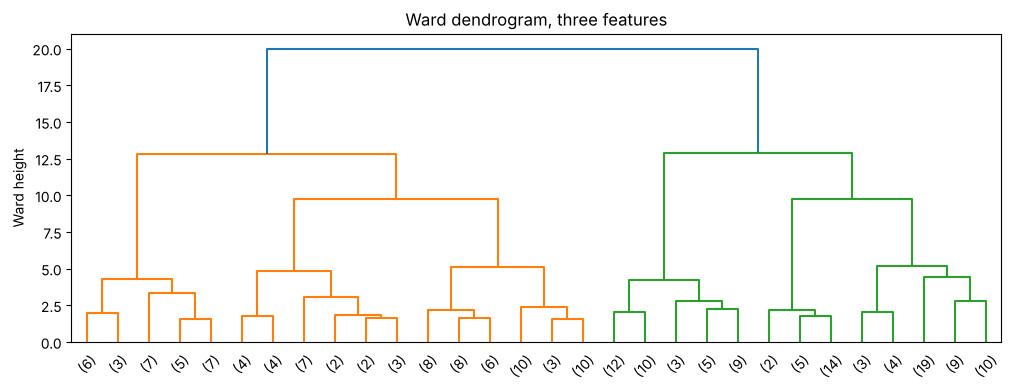

          cophenetic  silhouette                     sizes
linkage                                                   
single         0.542      -0.043      [193, 2, 2, 1, 1, 1]
complete       0.593       0.375  [57, 39, 35, 32, 21, 16]
average        0.668       0.390   [54, 52, 39, 31, 20, 4]
ward           0.626       0.420  [45, 45, 39, 28, 22, 21]
ARI(ward, k-means)=0.89
          Age  Annual Income (k$)  Spending Score (1-100)   n
cluster                                                      
1        43.9                91.3                    16.7  28
2        44.3                25.8                    20.3  22
3        56.4                55.3                    48.4  45
4        32.7                86.5                    82.1  39
5        24.8                25.6                    80.2  21
6        27.4                57.5                    45.8  45


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import squareform, pdist
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

# 1. Four cities
M = np.array([[0, 2, 6, 10], [2, 0, 5, 9], [6, 5, 0, 4], [10, 9, 4, 0]])
for method in ["single", "complete"]:
    print(method, linkage(squareform(M), method=method)[:, 2].tolist())

# 2. Ward dendrogram on three standardized features
url = "https://raw.githubusercontent.com/tirthajyoti/Machine-Learning-with-Python/master/Datasets/Mall_Customers.csv"
mall = pd.read_csv(url)
cols = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
Xs = StandardScaler().fit_transform(mall[cols])
Z = linkage(Xs, method="ward")
last = Z[-8:, 2][::-1]
print(f"last heights={last.round(2).tolist()}")
print(f"gaps={(-np.diff(last)).round(2).tolist()}")
fig, ax = plt.subplots(figsize=(12, 4))
dendrogram(Z, truncate_mode="lastp", p=30, ax=ax)
ax.set(ylabel="Ward height", title="Ward dendrogram, three features")
plt.show()

# 3. Linkage comparison
k = 6
d = pdist(Xs)
rows = []
for method in ["single", "complete", "average", "ward"]:
    Zm = linkage(Xs, method=method)
    lab = fcluster(Zm, t=k, criterion="maxclust")
    rows.append({"linkage": method, "cophenetic": cophenet(Zm, d)[0], "silhouette": silhouette_score(Xs, lab),
                 "sizes": sorted(np.bincount(lab)[1:].tolist(), reverse=True)})
print(pd.DataFrame(rows).set_index("linkage").round(3).to_string())

# 4. Ward vs k-means, and Ward profile
ward = fcluster(Z, t=k, criterion="maxclust")
km = KMeans(k, n_init=10, random_state=42).fit_predict(Xs)
print(f"ARI(ward, k-means)={adjusted_rand_score(ward, km):.2f}")
print(mall.assign(cluster=ward).groupby("cluster")[cols].mean().round(1).assign(n=np.bincount(ward)[1:]))

<div dir="rtl">

### پاسخ‌های کلیدی

- **چهار شهر:** در هر دو روش A و B در ارتفاع ۲ و C و D در ارتفاع ۴ ادغام می‌شوند؛ ادغام نهایی در پیوند تکی در ارتفاع ۵ و در پیوند کامل در ارتفاع ۱۰ است. اگر خود ماتریس مربعی به `linkage` داده شود، سطرها نقطه تفسیر می‌شوند و نتیجه اشتباه است.
- **دندروگرام وارد با سه ویژگی:** بزرگ‌ترین شکاف (۷.۰۹) میان ارتفاع ۲۰ و ۱۲.۹۱ است و فقط **دو** خوشه پیشنهاد می‌کند که برای بازاریابی بیش از حد کلی است. شکاف دوم (۴.۵۶) میان ۹.۷۲ و ۵.۱۶ است و **شش** خوشه می‌دهد؛ ما k برابر ۶ را انتخاب کردیم.
- **مقایسه پیوندها با شش خوشه:** پیوند تکی با ۱۹۳ مشتری در یک خوشه، ضریب نیم‌رخ منفی (۰.۰۴۳−) دارد. روش وارد بهترین نیم‌رخ (۰.۴۲۰) و متعادل‌ترین اندازه‌ها را دارد، در حالی که بالاترین ضریب کوفنتیک (۰.۶۶۸) مال پیوند میانگین است.
- **وارد در برابر k-Means:** شاخص ARI برابر ۰.۸۹؛ دو روش تقریباً همان خوشه‌ها را می‌سازند.
- **نیم‌رخ شش خوشه وارد:** پردرآمد کم‌خرج (۲۸ نفر، سن ۴۴)، کم‌درآمد کم‌خرج (۲۲ نفر، سن ۴۴)، مسن‌ترهای میانه‌رو (۴۵ نفر، سن ۵۶)، پردرآمد پرخرج (۳۹ نفر، سن ۳۳)، جوانان کم‌درآمد پرخرج (۲۱ نفر، سن ۲۵) و جوانان میانه‌رو (۴۵ نفر، سن ۲۷). افزودن سن، خوشه میانی جلسه قبل را به دو گروه جوان و مسن شکست.

</div>